## Descrição

Esse notebook foi construído para realizar os desafios propostos no final de cada aula do curso **Pandas: limpeza e tratamento de dados**

## Aula 1: Conhecendo os dados

### Desafio 1
Ao normalizar o objeto JSON durante a aula passamos simplesmente pd.json_normalize(<dados>) mas o método json_normalize possui diversos parâmetros para trabalhar com estruturas de dados mais complexas.

Você recebeu a tarefa de normalizar o seguinte arquivo JSON chamado [informacoes.json](https://cdn3.gnarususercontent.com.br/2929-pandas/informacoes.json) referente a algumas informações de identificação de um cliente.

O resultado final deve ser um Pandas DataFrame que possui a seguinte estrutura:

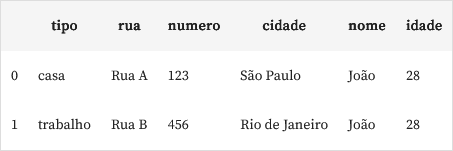

In [ ]:
import pandas as pd
import json

with open(r"C:\Users\Dionatan\OneDrive\Documentos\GitHub\Cursos\Data-Science\Python\Pandas\Pandas_ETL_Completo\informacoes.json") as f:
  json_bruto = json.load(f)

dados_normalizados = pd.json_normalize(json_bruto, record_path='enderecos', meta=['nome','idade'])
dados_normalizados.head() 

,tipo,rua,numero,cidade,nome,idade
0,casa,Rua A,123,SÃ£o Paulo,JoÃ£o,28
1,trabalho,Rua B,456,Rio de Janeiro,JoÃ£o,28


### Desafio 2
Você recebeu e fez o download o arquivo JSON chamado [dados.json](https://cdn3.gnarususercontent.com.br/2929-pandas/dados.json). <br>
Sua tarefa é realizar alguns tratamentos e deixar esse arquivo JSON como um Pandas DataFrame, sem dados vazios e com a tipagem das colunas de forma correta.

In [34]:
import pandas as pd
import json

with open(r"C:\Users\Dionatan\OneDrive\Documentos\GitHub\Cursos\Data-Science\Python\Pandas\Pandas_ETL_Completo\dados.json") as f:
  json_bruto = json.load(f)

dados_normalizados = pd.json_normalize(json_bruto, record_path='pessoas')
dados_normalizados['idade'] = dados_normalizados['idade'].astype(int)
dados_filtrados = dados_normalizados[dados_normalizados['endereco.rua'] != ""]
dados_filtrados

,nome,idade,telefones,endereco.rua,endereco.numero,endereco.cidade
0,JoÃ£o,25,"[11 1111-1111, 11 2222-2222]",Rua A,123,SÃ£o Paulo


In [31]:
dados_normalizados['idade'].astype(int)

0    25
1    30
Name: idade, dtype: int64

### Desafio 3
Confira a quantidade de linhas e colunas do DataFrame

In [ ]:
dados.shape

(18, 4)

### Desafio 4
Explore as colunas do DataFrame e analise os tipos dos dados presentes em cada coluna

In [ ]:
dados.columns

Index(['Nome', 'Idade', 'Notas', 'Aprovado'], dtype='object')

In [ ]:
dados['Notas']

0      7.5
1      NaN
2      2.5
3      5.0
4     10.0
5      NaN
6      7.0
7      6.0
8      5.6
9      NaN
10     NaN
11     4.5
12     9.5
13     9.0
14     NaN
15     7.0
16     NaN
17     8.0
Name: Notas, dtype: float64

In [ ]:
dados[['Nome', 'Aprovado']]

,Nome,Aprovado
0,Ary,True
1,Ana,False
2,Cátia,False
3,Denis,False
4,Beto,True
5,Bruna,False
6,Dara,True
7,Carlos,True
8,Alice,False
9,Vitor,False


In [ ]:
dados.dtypes

Nome         object
Idade         int64
Notas       float64
Aprovado       bool
dtype: object

### **Extra**
Calcule algumas estatísticas descritivas básicas dos dados do DataFrame (média, desvio padrão, etc) - Dica: pesquise pelo método **describe**

In [ ]:
dados.describe()

,Idade,Notas
count,18.000000,12.000000
mean,25.500000,6.800000
std,6.070662,2.204953
min,18.000000,2.500000
25%,21.000000,5.450000
50%,24.500000,7.000000
75%,28.750000,8.250000
max,37.000000,10.000000


## Aula 2: Análise exploratória dos dados

Para os desafios dessa aula, vamos utilizar a mesma base de dados que estamos utilizando para o desenvolvimento do nosso projeto. Sendo assim, na célula abaixo vamos realizar a importação dessa base de dados e aplicar as transformações já realizadas até o momento da aula 2.

In [ ]:
# importando a base de dados
url = 'https://raw.githubusercontent.com/alura-cursos/pandas-conhecendo-a-biblioteca/main/base-de-dados/aluguel.csv'
dados = pd.read_csv(url, sep=';')

In [ ]:
imoveis_comerciais = ['Conjunto Comercial/Sala', 
                      'Prédio Inteiro', 'Loja/Salão', 
                      'Galpão/Depósito/Armazém', 
                      'Casa Comercial', 'Terreno Padrão',
                      'Loja Shopping/ Ct Comercial',
                      'Box/Garagem', 'Chácara',
                      'Loteamento/Condomínio', 'Sítio',
                      'Pousada/Chalé', 'Hotel', 'Indústria']
                      
# removendo imóveis comerciais
df = dados.query('@imoveis_comerciais not in Tipo')

# selecionando apenas imóveis do tipo apartamento
df = df.query('Tipo == "Apartamento"')

# visualizando a base de dados
df.head()

,Tipo,Bairro,Quartos,Vagas,Suites,Area,Valor,Condominio,IPTU
3,Apartamento,Centro,1,0,0,15,800.0,390.0,20.0
4,Apartamento,Higienópolis,1,0,0,48,800.0,230.0,NaN
5,Apartamento,Vista Alegre,3,1,0,70,1200.0,NaN,NaN
6,Apartamento,Cachambi,2,0,0,50,1300.0,301.0,17.0
10,Apartamento,Centro,1,0,0,36,1200.0,NaN,NaN


### Desafio 1
Calcular a média de quartos por apartamento

In [ ]:
df['Quartos'].mean()

2.481568707761622

### Desafio 2
Conferir quantos bairros únicos existem na nossa base de dados

In [ ]:
len(df['Bairro'].unique())

149

In [ ]:
df['Bairro'].nunique()

149

### Desafio 3
Analisar quais bairros possuem a média de valor de aluguel mais elevadas

In [ ]:
df.groupby('Bairro')[['Valor']].mean().sort_values('Valor')

,Valor
Bairro,
Ricardo de Albuquerque,340.000000
Paciência,510.000000
Santa Cruz,590.000000
Cosmos,610.000000
Inhoaíba,650.000000
...,...
Botafogo,9369.207116
Ipanema,9487.205317
Cidade Jardim,12000.000000


### Desafio 4
Criar um gráfico de barras verticais que apresente os 5 bairros com a média de valor de aluguel mais elevadas

In [ ]:
df.groupby('Bairro')[['Valor']].mean().sort_values('Valor').head()

,Valor
Bairro,
Ricardo de Albuquerque,340.0
Paciência,510.0
Santa Cruz,590.0
Cosmos,610.0
Inhoaíba,650.0


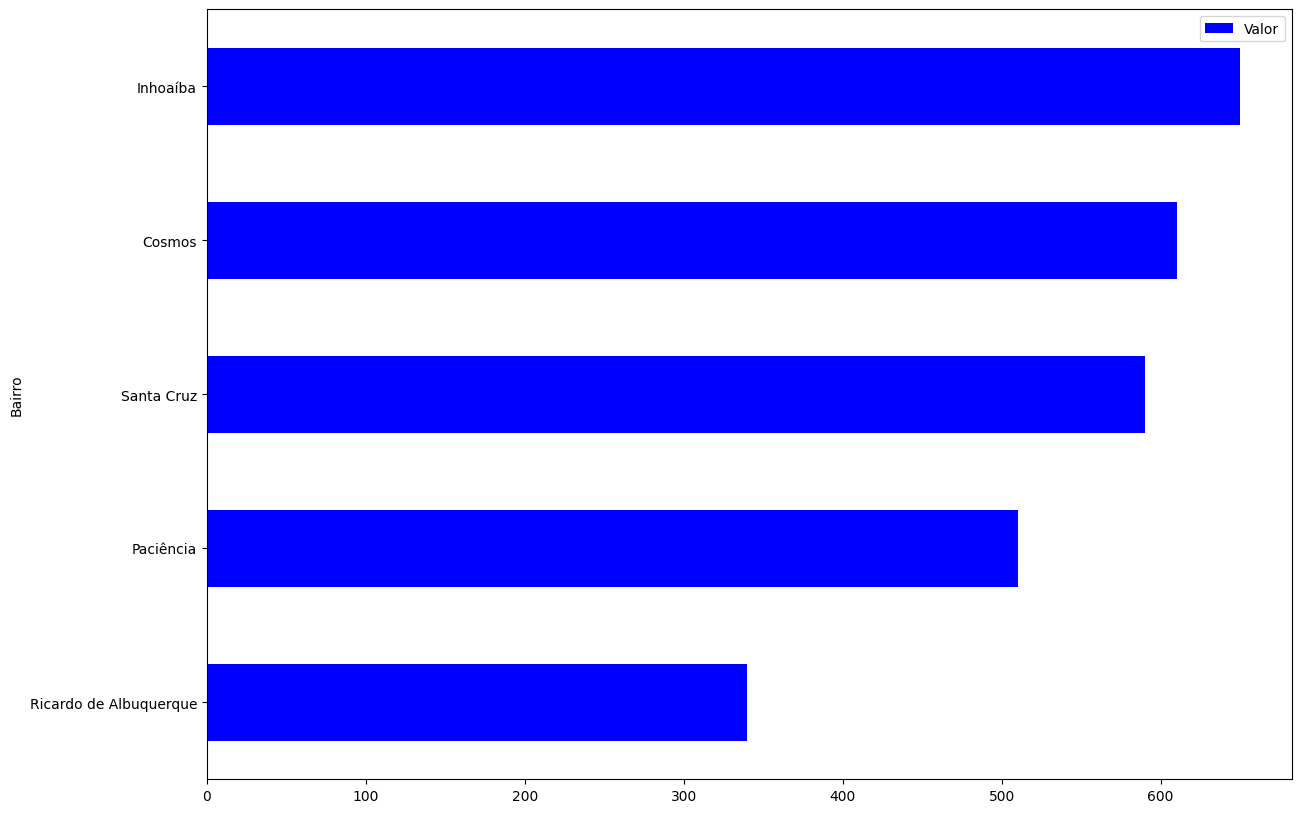

In [ ]:
df_bairros = df.groupby('Bairro')[['Valor']].mean().sort_values('Valor').head()

df_bairros.plot(kind='barh', figsize=(14,10), color='blue'); 

## Aula 3

In [ ]:
# Importando novamente os dados

url = 'https://raw.githubusercontent.com/alura-cursos/pandas-conhecendo-a-biblioteca/main/desafios/alunos.csv'
dados = pd.read_csv(url)
dados

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,NaN,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,NaN,False
6,Dara,21,7.0,True
7,Carlos,19,6.0,True
8,Alice,35,5.6,False
9,Vitor,28,NaN,False


### Desafio 1
Verifique se a base de dados possui dados nulos e caso tenha, realize o tratamento desses dados nulos

In [ ]:
dados.isnull().sum()

Nome        0
Idade       0
Notas       6
Aprovado    0
dtype: int64

In [ ]:
dados = dados.fillna(0)
dados

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,0.0,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,0.0,False
6,Dara,21,7.0,True
7,Carlos,19,6.0,True
8,Alice,35,5.6,False
9,Vitor,28,0.0,False


In [ ]:
dados.isnull().sum()

Nome        0
Idade       0
Notas       0
Aprovado    0
dtype: int64

### Desafio 2
Os alunos "Alice" e "Carlos", não fazem mais parte da turma. Sendo assim, remova-os da base de dados

In [ ]:
dados.query('Nome == "Alice" | Nome == "Carlos"')

,Nome,Idade,Notas,Aprovado
7,Carlos,19,6.0,True
8,Alice,35,5.6,False


In [ ]:
dados.query('Nome == "Alice" | Nome == "Carlos"').index

Index([7, 8], dtype='int64')

In [ ]:
alunos_a_remover = dados.query('Nome == "Alice" | Nome == "Carlos"').index

dados.drop(alunos_a_remover, axis=0, inplace=True)

In [ ]:
dados.query('Nome == "Alice" | Nome == "Carlos"')

,Nome,Idade,Notas,Aprovado


### Desafio 3
Aplique um filtro que selecione apenas os alunos que foram aprovados

In [ ]:
dados['Aprovado'] == True

0      True
1     False
2     False
3     False
4      True
5     False
6      True
9     False
10    False
11    False
12     True
13     True
14    False
15     True
16    False
17     True
Name: Aprovado, dtype: bool

In [ ]:
selecao = dados['Aprovado'] == True
dados[selecao]

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
4,Beto,21,10.0,True
6,Dara,21,7.0,True
12,Sthefanie,26,9.5,True
13,Mirla,25,9.0,True
15,Mylena,29,7.0,True
17,Nadia,34,8.0,True


### Desafio 4
Salve o DataFrame que possui apenas os alunos aprovados em um arquivo csv chamado "alunos_aprovados.csv"

In [ ]:
alunos_aprovados = dados[selecao]

In [ ]:
alunos_aprovados.to_csv('alunos_aprovados.csv', index=False)

In [ ]:
pd.read_csv('alunos_aprovados.csv')

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Beto,21,10.0,True
2,Dara,21,7.0,True
3,Sthefanie,26,9.5,True
4,Mirla,25,9.0,True
5,Mylena,29,7.0,True
6,Nadia,34,8.0,True


### **Extra**
Ao conferir as notas dos alunos aprovados, notamos que algumas notas estavam incorretas. As alunas que tiraram nota 7.0, na verdade tinham um ponto extra que não foi contabilizado. Sendo assim, substitua as notas 7.0 da base de dados por 8.0. **Dica**: pesquise pelo método **replace**

In [ ]:
alunos_aprovados

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
4,Beto,21,10.0,True
6,Dara,21,7.0,True
12,Sthefanie,26,9.5,True
13,Mirla,25,9.0,True
15,Mylena,29,7.0,True
17,Nadia,34,8.0,True


In [ ]:
alunos_aprovados.replace(7.0, 8.0)

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
4,Beto,21,10.0,True
6,Dara,21,8.0,True
12,Sthefanie,26,9.5,True
13,Mirla,25,9.0,True
15,Mylena,29,8.0,True
17,Nadia,34,8.0,True


In [ ]:
alunos_aprovados = alunos_aprovados.replace(7.0, 8.0)
alunos_aprovados

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
4,Beto,21,10.0,True
6,Dara,21,8.0,True
12,Sthefanie,26,9.5,True
13,Mirla,25,9.0,True
15,Mylena,29,8.0,True
17,Nadia,34,8.0,True


## Aula 4

In [ ]:
import pandas as pd

In [ ]:
# Importando novamente os dados

url = 'https://raw.githubusercontent.com/alura-cursos/pandas-conhecendo-a-biblioteca/main/desafios/alunos.csv'
dados = pd.read_csv(url)
dados

,Nome,Idade,Notas,Aprovado
0,Ary,20,7.5,True
1,Ana,18,NaN,False
2,Cátia,27,2.5,False
3,Denis,18,5.0,False
4,Beto,21,10.0,True
5,Bruna,23,NaN,False
6,Dara,21,7.0,True
7,Carlos,19,6.0,True
8,Alice,35,5.6,False
9,Vitor,28,NaN,False


### Desafio 1
Os alunos participaram de uma atividade extracurricular e ganharam pontos extras. Esses pontos extras correspondem a 40% da nota atual de cada um deles. Com base nisso, crie uma coluna chamada "Pontos_extras" que contenha os pontos extras de cada aluno, ou seja, 40% da nota atual deles

In [ ]:
dados['Pontos_extras'] = dados['Notas'].apply(lambda x: x*0.4)
dados

,Nome,Idade,Notas,Aprovado,Pontos_extras
0,Ary,20,7.5,True,3.00
1,Ana,18,NaN,False,NaN
2,Cátia,27,2.5,False,1.00
3,Denis,18,5.0,False,2.00
4,Beto,21,10.0,True,4.00
5,Bruna,23,NaN,False,NaN
6,Dara,21,7.0,True,2.80
7,Carlos,19,6.0,True,2.40
8,Alice,35,5.6,False,2.24
9,Vitor,28,NaN,False,NaN


### Desafio 2
Crie mais uma coluna, chamada "Notas_finais" que possua as notas de cada aluno somada com os pontos extras

In [ ]:
dados['Notas_finais'] = dados['Notas'] + dados['Pontos_extras']
dados

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais
0,Ary,20,7.5,True,3.00,10.50
1,Ana,18,NaN,False,NaN,NaN
2,Cátia,27,2.5,False,1.00,3.50
3,Denis,18,5.0,False,2.00,7.00
4,Beto,21,10.0,True,4.00,14.00
5,Bruna,23,NaN,False,NaN,NaN
6,Dara,21,7.0,True,2.80,9.80
7,Carlos,19,6.0,True,2.40,8.40
8,Alice,35,5.6,False,2.24,7.84
9,Vitor,28,NaN,False,NaN,NaN


### Desafio 3
Como os alunos ganharam pontos extras, alguns que não tinham sido aprovados antes podem ter sido aprovados agora. Com base nisso, crie uma coluna chamada "Aprovado_final" com os seguintes valores:

* True: caso o aluno esteja aprovado (nota final deve ser maior ou igual a 6);
* False: caso o aluno esteja reprovado (nota final deve ser menor que 6).


In [ ]:
dados['Aprovado_final'] = dados['Notas_finais'].apply(lambda x: True if x >= 6 else False)
dados

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
0,Ary,20,7.5,True,3.00,10.50,True
1,Ana,18,NaN,False,NaN,NaN,False
2,Cátia,27,2.5,False,1.00,3.50,False
3,Denis,18,5.0,False,2.00,7.00,True
4,Beto,21,10.0,True,4.00,14.00,True
5,Bruna,23,NaN,False,NaN,NaN,False
6,Dara,21,7.0,True,2.80,9.80,True
7,Carlos,19,6.0,True,2.40,8.40,True
8,Alice,35,5.6,False,2.24,7.84,True
9,Vitor,28,NaN,False,NaN,NaN,False


### Desafio 4
Faça uma seleção e verifique quais alunos não tinham sido aprovados anteriormente, mas foram aprovados após a soma dos pontos extras

In [ ]:
dados.query('Aprovado == False & Aprovado_final == True')

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
3,Denis,18,5.0,False,2.00,7.00,True
8,Alice,35,5.6,False,2.24,7.84,True
11,Igor,24,4.5,False,1.80,6.30,True


In [ ]:
selecao = (dados['Aprovado'] == False) & (dados['Aprovado_final'] == True)
dados[selecao]

,Nome,Idade,Notas,Aprovado,Pontos_extras,Notas_finais,Aprovado_final
3,Denis,18,5.0,False,2.00,7.00,True
8,Alice,35,5.6,False,2.24,7.84,True
11,Igor,24,4.5,False,1.80,6.30,True


### Outliers
Existem várias técnicas para detectar outliers em um conjunto de dados. Algumas das mais comuns são: Z-score, regra dos 3 sigmas e a análise de dispersão.

1) Z-score:

O z-score é uma medida estatística que indica a quantos múltiplos do desvio-padrão um dado está distante da média. Para detectar outliers utilizando essa medida, basta calcular o z-score de cada dado e verificar se ele está muito distante da média. Se o z-score for maior do que um determinado limite, podemos considerar esse dado como um outlier.

O limite geralmente utilizado é de 3 desvios-padrões, ou seja, se o z-score de um dado for maior do que 3, podemos considerá-lo como um outlier.


In [54]:
import numpy as np

# Dados de exemplo
data = np.array([100, 900, 30, 40, 150, 50, 60, 70, 80, 90, 100, 350])

# Cálculo do z-score
z_scores = (data - np.median(data)) / np.std(data)

# Limite para considerar um dado como outlier
limite = 3

# Identificação dos outliers
outliers = data[np.abs(np.around(z_scores)) >= limite]

print("Outliers encontrados:", outliers)

Outliers encontrados: [900]


2) Regra dos 3 sigmas:

A regra dos 3 sigmas é uma técnica que utiliza a distribuição normal para identificar outliers. Ela diz que cerca de 99,7% dos dados estarão dentro de 3 desvios padrão da média. Portanto, se um dado estiver a mais de 3 desvios padrão da média, podemos considerá-lo como um outlier.

In [55]:
import numpy as np

# Criar um array com os dados
dados = np.array([0, 10, 12, 13, 15, 16, 18, 20, 22, 25, 30, 35, 40, 50, 350])

# Calcular a média e o desvio padrão do conjunto de dados
media = np.mean(dados)
desvio_padrao = np.std(dados)

# Definir o limite superior e inferior para identificar os outliers
limite_superior = media + (3 * desvio_padrao)
limite_inferior = media - (3 * desvio_padrao)

# Identificar os outliers no conjunto de dados
outliers = dados[(dados > limite_superior) | (dados < limite_inferior)]

print("Outliers:", outliers)

Outliers: [350]


3) Análise de dispersão

A análise de dispersão é uma técnica que utiliza gráficos para identificar outliers. Um gráfico comumente utilizado é o boxplot que mostra a distribuição dos dados em quartis. Os outliers são identificados como pontos fora dos limites superior e inferior do boxplot.

Outliers encontrados: [-100]


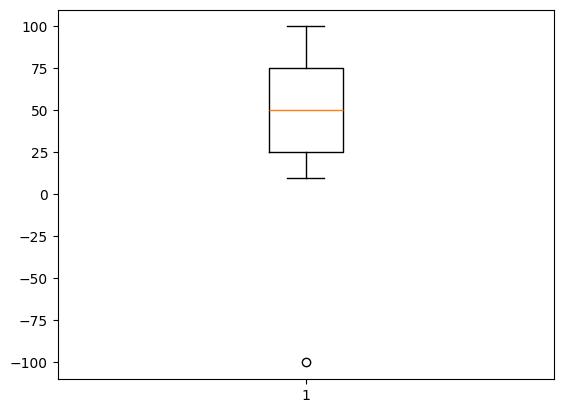

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Dados de exemplo
data = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

# Criação do boxplot
fig, ax = plt.subplots()
ax.boxplot(data)

# Identificação dos outliers
outliers = data[(data < np.percentile(data, 25) - (1.5 * (np.percentile(data, 75) - np.percentile(data, 25)))) |
                (data > np.percentile(data, 75) + (1.5 * (np.percentile(data, 75) - np.percentile(data, 25))))]

print("Outliers encontrados:", outliers)

Você trabalha em um banco como cientista de dados e recebeu o seguinte conjunto de dados para analisar:

In [75]:
import pandas as pd

# criando um DataFrame com 30 transações aleatórias
df = pd.DataFrame({
    'ID da transação': range(1, 31),
    'Valor da transação': [100, 200, 150, 500, 300, 913, 250, 400, 200, 150, 
                           200, 200, 400, 300, 150, 301, 805, 300, 400, 250, 
                           150, 100, 500, 600, 200, 350, 100, 250, 800, 250],
    'Data da transação': pd.date_range(start='2022-01-01', end='2022-01-30', freq='D'),
    'Local da transação': ['São Paulo, Brasil', 'Rio de Janeiro, Brasil', 'Belo Horizonte, Brasil', 'São Paulo, Brasil', 
                           'São Paulo, Brasil', 'Nova Iorque, EUA', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'Rio de Janeiro, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'São Paulo, Brasil', 'Los Angeles, EUA', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'São Paulo, Brasil', 'Miami, EUA', 'São Paulo, Brasil']
})

Foi informado que nessa base de dados há possíveis fraudes que podem ser identificadas através dos outliers no “valor da transação”. Basicamente a fraude seria um outlier.

Sua missão é construir uma função que recebe dois parâmetros, a coluna que você quer analisar se tem outlier e o DataFrame em questão. A intenção de fazer isso é aproveitar novamente essa função tanto para outras colunas quanto para outros DataFrames futuramente em outras análises. O método que deve ser implementado para identificação do outlier é do intervalo interquartil.

Como podemos fazer isso?

Outliers encontrados: 5     913
16    805
28    800
Name: Valor da transação, dtype: int64


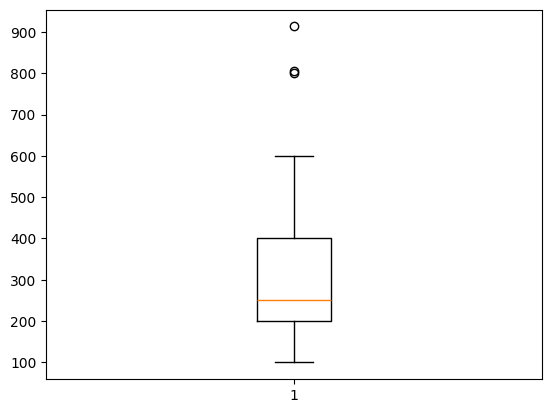

In [79]:
# Criação do boxplot
fig, ax = plt.subplots()
ax.boxplot(df['Valor da transação'])

# Identificação dos outliers
outliers = df['Valor da transação'][(df['Valor da transação'] < np.percentile(df['Valor da transação'], 25) - (1.5 * (np.percentile(df['Valor da transação'], 75) - np.percentile(df['Valor da transação'], 25)))) |
                (df['Valor da transação'] > np.percentile(df['Valor da transação'], 75) + (1.5 * (np.percentile(df['Valor da transação'], 75) - np.percentile(df['Valor da transação'], 25))))]

print("Outliers encontrados:", outliers)

In [85]:
print("Dados das possíveis fraudes:")
df.loc[[5,16,28]]

Dados das possíveis fraudes:


,ID da transação,Valor da transação,Data da transação,Local da transação
5,6,913,2022-01-06,"Nova Iorque, EUA"
16,17,805,2022-01-17,"Los Angeles, EUA"
28,29,800,2022-01-29,"Miami, EUA"
